Columns: Index(['Soil Moisture', 'Soil Humidity', 'Air temperature (C)',
       'Air humidity (%)', 'Status'],
      dtype='object')
After filtering: (11055, 3)

===== FINAL RESULTS =====
Accuracy: 0.877431026684758
Precision: 0.8918269230769231
Recall: 0.8911128903122498
F1 Score: 0.8914697637164598

Confusion Matrix:
 [[ 827  135]
 [ 136 1113]]


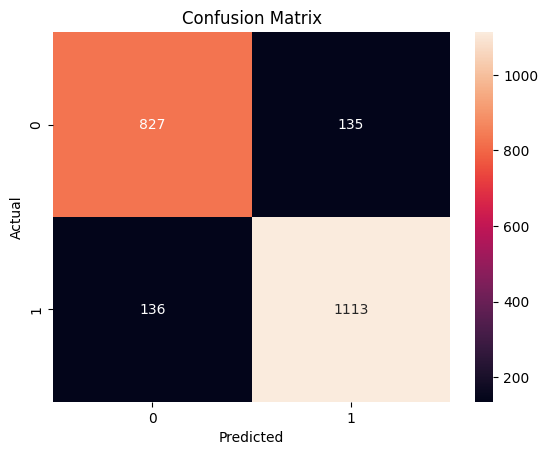

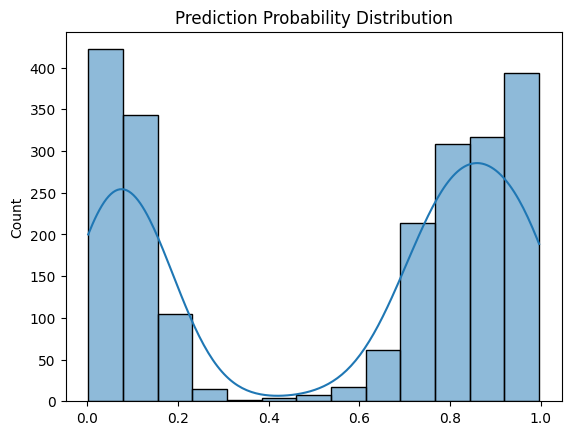

model.pkl and scaler.pkl saved


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

from xgboost import XGBClassifier

df = pd.read_csv("TARP_MODERATE_CONFIDENCE.csv")

# clean column names
df.columns = df.columns.str.strip()
print("Columns:", df.columns)

le = LabelEncoder()
df['Status'] = le.fit_transform(df['Status'])

X = df[['Soil Moisture', 'Air humidity (%)', 'Air temperature (C)']].copy()
y = df['Status']

for col in X.columns:
    X.loc[:, col] = X[col] + 0.15 * (X[col] ** 2)
    X.loc[:, col] = X[col] + np.random.normal(0, 0.12, size=len(X))

temp_model = XGBClassifier(n_estimators=200, random_state=42, eval_metric='logloss')
temp_model.fit(X, y)

conf = np.max(temp_model.predict_proba(X), axis=1)

mask = conf > 0.65
X = X[mask]
y = y[mask]

print("After filtering:", X.shape)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

model = XGBClassifier(
    n_estimators=220,
    learning_rate=0.09,
    max_depth=3,
    min_child_weight=6,
    subsample=0.65,
    colsample_bytree=0.65,
    gamma=0.6,
    reg_alpha=1.5,
    reg_lambda=4,
    scale_pos_weight=(len(y_train)-sum(y_train))/sum(y_train),
    random_state=42,
    eval_metric='logloss'
)

model.fit(X_train, y_train)

y_prob = model.predict_proba(X_test)[:, 1]
threshold = 0.68
y_pred = (y_prob > threshold).astype(int)

print("\n===== FINAL RESULTS =====")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

plt.figure()
sns.histplot(y_prob, kde=True)
plt.title("Prediction Probability Distribution")
plt.show()

joblib.dump(model, "model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("model.pkl and scaler.pkl saved")